# 05 · Không gian: Quận, vùng A01–A08 và tọa độ

Đề yêu cầu có hình thể hiện dữ liệu theo không gian (bản đồ) và có KPI theo `neighbourhood_cleansed`. Trong khi đó, file phân công lại chia London thành tám vùng hình chữ nhật.
Notebook này đặt hai cách chia vùng lên cùng một bản đồ để thấy chúng khác nhau thế nào. Nó cũng đối chiếu tên quận trong listings với
file GeoJSON, và đối chiếu tọa độ của listing với hình chữ nhật của vùng được giao.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})

TEN_CAU_HINH = "london.yaml"   # Đổi file cấu hình ở đây nếu khảo sát thành phố/mốc khác.


def tim_thu_muc_du_an(thu_muc_bat_dau: Path) -> Path:
    """Đi ngược lên các thư mục cha cho tới khi gặp configs/<TEN_CAU_HINH>."""
    # Vòng lặp qua các thư mục cha (vài cấp), không phải qua dòng dữ liệu.
    for thu_muc in [thu_muc_bat_dau, *thu_muc_bat_dau.parents]:
        if (thu_muc / "configs" / TEN_CAU_HINH).is_file():
            return thu_muc

    raise FileNotFoundError(f"Không tìm thấy thư mục dự án chứa configs/{TEN_CAU_HINH}")


THU_MUC_DU_AN = tim_thu_muc_du_an(Path.cwd().resolve())

with (THU_MUC_DU_AN / "configs" / TEN_CAU_HINH).open("r", encoding="utf-8-sig") as f:
    cau_hinh = yaml.safe_load(f)

thanh_pho = cau_hinh["city"]
snapshots = [str(snapshot) for snapshot in cau_hinh["snapshots"]]   # YAML đọc ngày không nháy thành date
moc_gia = max(snapshots)   # Quy tắc của nhóm: chỉ mốc cuối được dùng giá
THU_MUC_RAW = THU_MUC_DU_AN / "data" / "raw" / thanh_pho
THU_MUC_PHAN_CONG = THU_MUC_DU_AN / "data" / "assignment"

phan_cong_listings = pd.read_csv(THU_MUC_PHAN_CONG / "listings.csv", dtype=str, keep_default_na=False)
phan_cong_reviews = pd.read_csv(THU_MUC_PHAN_CONG / "reviews.csv", dtype=str, keep_default_na=False)
phan_cong_vung = pd.read_csv(THU_MUC_PHAN_CONG / "areas.csv", dtype={"analysis_area": str}, keep_default_na=False)
cac_listing_id = set(phan_cong_listings["listing_id"])
cac_review_id = set(phan_cong_reviews["review_id"])

print("Thư mục dự án :", THU_MUC_DU_AN.name)
print("Thành phố     :", thanh_pho, "| tiền tệ:", cau_hinh["currency"])
print("Các mốc       :", snapshots, "| mốc dùng giá:", moc_gia)
print("Phân công     :", len(cac_listing_id), "listing,", len(cac_review_id), "review")

import hashlib
import geopandas as gpd

Thư mục dự án : 2627-LTXLDL-Airbnb-dse2049_7-nhom15
Thành phố     : london | tiền tệ: GBP
Các mốc       : ['2025-09-14', '2025-12-13', '2026-03-21', '2026-06-19'] | mốc dùng giá: 2026-06-19
Phân công     : 1000 listing, 5000 review


## 1. File GeoJSON ranh giới quận

Mỗi mốc có một file `neighbourhoods.geojson`. Ô dưới đây tính mã băm SHA-256 của bốn file. Mã băm là một chuỗi ký tự đại diện cho nội dung file,
nên hai file có cùng mã băm thì giống nhau đến từng byte.

In [2]:
ma_bam = {s: hashlib.sha256((THU_MUC_RAW / s / "neighbourhoods.geojson").read_bytes()).hexdigest()[:16] for s in snapshots}
print(ma_bam)
print("Bốn file giống hệt nhau:", len(set(ma_bam.values())) == 1)

quan = gpd.read_file(THU_MUC_RAW / moc_gia / "neighbourhoods.geojson")
print("CRS:", quan.crs, "| số quận:", len(quan), "| kiểu hình học:", quan.geom_type.value_counts().to_dict())
quan.head()

{'2025-09-14': '35be510154d72771', '2025-12-13': '35be510154d72771', '2026-03-21': '35be510154d72771', '2026-06-19': '35be510154d72771'}
Bốn file giống hệt nhau: True


CRS: EPSG:4326 | số quận: 33 | kiểu hình học: {'MultiPolygon': 33}


,neighbourhood,neighbourhood_group,geometry
0,Kingston upon Thames,None,"MULTIPOLYGON (((-0.33066 51.32901, -0.33057 51.32909, -0.33048 51.32915, -0...."
1,Croydon,None,"MULTIPOLYGON (((-0.06399 51.31864, -0.06405 51.31861, -0.06409 51.3186, -0.0..."
2,Bromley,None,"MULTIPOLYGON (((0.01216 51.2996, 0.01199 51.29979, 0.01191 51.29995, 0.01183..."
3,Hounslow,None,"MULTIPOLYGON (((-0.24454 51.4887, -0.24466 51.48868, -0.24475 51.48869, -0.2..."
4,Ealing,None,"MULTIPOLYGON (((-0.41181 51.53408, -0.41186 51.53412, -0.4119 51.5342, -0.41..."


Bốn file giống hệt nhau, nên ranh giới quận không đổi qua bốn mốc và chỉ cần đọc một lần. File gồm 33 quận, tức 32 borough cộng với City of London.
Mỗi quận là một `MultiPolygon` (một hoặc nhiều đa giác), với tọa độ theo hệ WGS84 quen thuộc của GPS, ghi theo thứ tự kinh độ rồi vĩ độ. Cột
`neighbourhood_group` rỗng, khớp với việc cột `neighbourhood_group_cleansed` trong listings cũng rỗng.

## 2. Đối chiếu tên quận giữa listings và GeoJSON

Muốn tô màu bản đồ theo quận, ta phải ghép bảng số liệu với file GeoJSON qua tên quận: Cột `neighbourhood_cleansed` trong listings và thuộc tính
`neighbourhood` trong GeoJSON. Bài 13 nhắc rằng trước khi vẽ cần kiểm tra vùng không khớp, vì một tên viết khác đi một chữ cũng đủ làm quận đó
biến mất khỏi bản đồ. Ô dưới đây kiểm tra cả hai chiều: Listing nào có tên quận không có trong GeoJSON, và quận nào trong GeoJSON không có listing nào.

In [3]:
def doc_toa_do_listings(snapshot: str) -> pd.DataFrame:
    """Đọc tọa độ, quận và vùng phân công của listings nhóm ở một mốc."""
    du_lieu = pd.read_csv(
        THU_MUC_RAW / snapshot / "listings.csv.gz",
        usecols=["id", "latitude", "longitude", "neighbourhood_cleansed", "room_type"],
        dtype=str,
        keep_default_na=False,
    )
    du_lieu = du_lieu.loc[du_lieu["id"].isin(cac_listing_id)].rename(columns={"id": "listing_id"})
    du_lieu = du_lieu.merge(phan_cong_listings, on="listing_id", how="left", validate="one_to_one")

    # apply theo CỘT (2 cột tọa độ), không phải theo hàng.
    du_lieu[["latitude", "longitude"]] = du_lieu[["latitude", "longitude"]].apply(pd.to_numeric, errors="raise")
    return du_lieu


toa_do = {s: doc_toa_do_listings(s) for s in snapshots}   # Mỗi mốc một bảng (4 lần đọc file)
ten_quan_geojson = quan["neighbourhood"]

# Vòng lặp qua từng mốc (4 lần), phép so khớp bên trong chạy trên cả cột.
for snapshot, du_lieu in toa_do.items():
    khop_ten = du_lieu["neighbourhood_cleansed"].isin(ten_quan_geojson)
    print(f"{snapshot}: {int(khop_ten.sum())}/1000 listing có tên quận khớp GeoJSON, "
          f"{du_lieu['neighbourhood_cleansed'].nunique()} quận khác nhau")

quan_khong_co_listing = ten_quan_geojson.loc[~ten_quan_geojson.isin(toa_do[moc_gia]["neighbourhood_cleansed"])]
print("Quận trong GeoJSON không có listing nào của nhóm:", quan_khong_co_listing.tolist())

2025-09-14: 1000/1000 listing có tên quận khớp GeoJSON, 33 quận khác nhau
2025-12-13: 1000/1000 listing có tên quận khớp GeoJSON, 33 quận khác nhau
2026-03-21: 1000/1000 listing có tên quận khớp GeoJSON, 33 quận khác nhau
2026-06-19: 1000/1000 listing có tên quận khớp GeoJSON, 33 quận khác nhau
Quận trong GeoJSON không có listing nào của nhóm: []


Ở cả bốn mốc, cả 1.000 listing đều mang tên quận có trong GeoJSON, và ngược lại không quận nào trong GeoJSON bị bỏ trống. Như vậy có thể ghép
số liệu theo quận vào bản đồ mà không mất vùng nào, và cũng không phải tự điền 0 cho quận vắng mặt.

Notebook chỉ đối chiếu theo tên, không kiểm tra tọa độ của listing có thật sự nằm trong đa giác của quận đó hay không. Phép kiểm tra điểm nằm trong
đa giác cần hàm hình học không có trong bài giảng. Ngoài ra, theo mô tả dữ liệu của Inside Airbnb, tọa độ của listing đã được làm mờ,
nên với listing nằm sát ranh giới, quận thật ngoài đời có thể khác quận ghi trong dữ liệu. Báo cáo nên có một câu chú thích cho giới hạn này.

## 3. Hai cách chia vùng trên cùng một bản đồ

**Cách đọc biểu đồ.** Bản đồ có ba lớp chồng lên nhau. Lớp nền là 33 quận, tô xám nhạt với đường viền xám. Lớp giữa là tám khung chữ nhật nét đứt, mỗi khung là một vùng phân tích, với tên A01 đến A08 ghi ở tâm khung. Lớp trên cùng là 1.000 chấm, mỗi chấm là một listing đặt theo tọa độ ở mốc cuối. Màu chấm cho biết vùng mà file phân công gán cho listing đó, theo chú thích ở góc dưới bên trái.

Nếu cách gán vùng khớp với các khung, mọi chấm cùng màu sẽ nằm gọn trong cùng một khung. Mục 4 kiểm tra điều này bằng số liệu thay vì bằng mắt. Ở trung tâm, các chấm đè lên nhau nên một mảng màu đặc có thể chứa nhiều listing hơn mắt thấy. Số listing chính xác của mỗi vùng là số `n` trong chú thích.

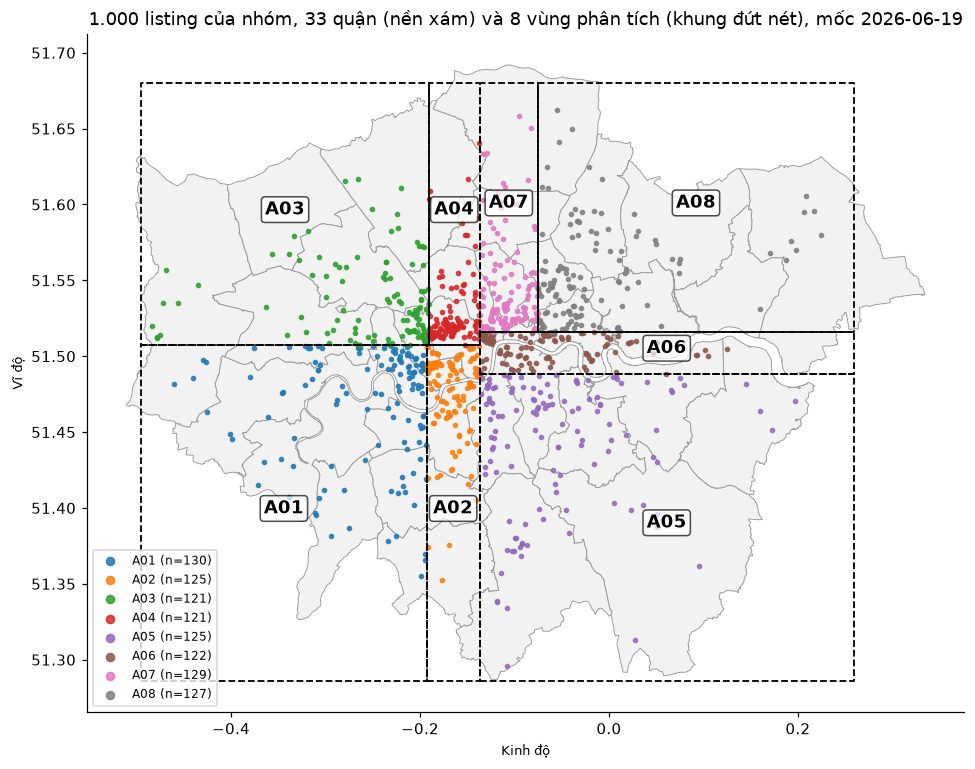

In [4]:
gdf = toa_do[moc_gia]
bien_vung = phan_cong_vung.astype({"lon_min": float, "lat_min": float, "lon_max": float, "lat_max": float})
bang_mau = dict(zip(sorted(bien_vung["analysis_area"]), plt.get_cmap("tab10").colors))

# Mỗi khung là đường gấp khúc đi qua 4 góc rồi quay về góc đầu. Khi nhận mảng 2 chiều,
# ax.plot vẽ mỗi cột thành một đường, nên 8 khung được vẽ trong một lần gọi (Bài 12).
x_khung = bien_vung[["lon_min", "lon_max", "lon_max", "lon_min", "lon_min"]].to_numpy().T
y_khung = bien_vung[["lat_min", "lat_min", "lat_max", "lat_max", "lat_min"]].to_numpy().T
tam_x = bien_vung[["lon_min", "lon_max"]].mean(axis=1)
tam_y = bien_vung[["lat_min", "lat_max"]].mean(axis=1)

fig, ax = plt.subplots(figsize=(11, 8))
quan.plot(ax=ax, color="#F2F2F2", edgecolor="#9A9A9A", linewidth=0.6)
ax.plot(x_khung, y_khung, color="black", linewidth=1.2, linestyle="--")

# Vòng lặp qua 8 vùng để mỗi vùng có màu và dòng chú thích riêng.
for ten_vung, nhom in gdf.groupby("analysis_area"):
    ax.scatter(nhom["longitude"], nhom["latitude"], s=7, color=bang_mau[ten_vung], alpha=0.85,
               label=f"{ten_vung} (n={len(nhom)})")

# ax.annotate chỉ ghi một nhãn mỗi lần gọi, nên cần vòng lặp qua 8 tâm khung.
for ten_vung, x, y in zip(bien_vung["analysis_area"], tam_x, tam_y):
    ax.annotate(ten_vung, (x, y), fontsize=12, fontweight="bold", ha="center",
                bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.7))

ax.set(title=f"1.000 listing của nhóm, 33 quận (nền xám) và 8 vùng phân tích (khung đứt nét), mốc {moc_gia}",
       xlabel="Kinh độ", ylabel="Vĩ độ")
ax.legend(loc="lower left", fontsize=8, markerscale=2)
ax.grid(False)
plt.show()

Tám khung hình chữ nhật cắt ngang ranh giới quận và không đi theo đường hành chính nào. Kích thước của chúng cũng rất khác nhau. A06 là một dải hẹp
chạy ngang qua trung tâm, còn A01 và A05 trải rộng ra cả vùng ngoại ô. Quan sát mật độ các điểm trên bản đồ, ta thấy listing của nhóm tập trung dày ở trung tâm và thưa dần ra
phía ngoài, nên một vùng rộng như A01 không có nhiều listing hơn một vùng hẹp như A06. Dù diện tích chênh nhau nhiều, số listing của
tám vùng chỉ dao động từ 121 đến 130.

Bảng chéo dưới đây đếm xem hai cách chia vùng chồng lên nhau đến mức nào.

In [5]:
bang_cheo = pd.crosstab(gdf["neighbourhood_cleansed"], gdf["analysis_area"])
so_vung_moi_quan = bang_cheo.gt(0).sum(axis=1).sort_values(ascending=False)
so_quan_moi_vung = bang_cheo.gt(0).sum(axis=0)

print("Số vùng A mà mỗi quận bị chia ra (top 6):", so_vung_moi_quan.head(6).to_dict())
print("Số quận có mặt trong mỗi vùng A:", so_quan_moi_vung.to_dict())
bang_cheo.loc[so_vung_moi_quan.index[:8]]

Số vùng A mà mỗi quận bị chia ra (top 6): {'Westminster': 6, 'Camden': 4, 'Lambeth': 3, 'Hammersmith and Fulham': 3, 'Barnet': 3, 'Haringey': 3}
Số quận có mặt trong mỗi vùng A: {'A01': 10, 'A02': 7, 'A03': 9, 'A04': 5, 'A05': 9, 'A06': 9, 'A07': 9, 'A08': 9}


analysis_area,A01,A02,A03,A04,A05,A06,A07,A08
neighbourhood_cleansed,,,,,,,,
Westminster,0,22,23,87,1,33,2,0
Camden,0,0,3,25,0,2,36,0
Lambeth,0,2,0,0,30,8,0,0
Hammersmith and Fulham,32,3,4,0,0,0,0,0
Barnet,0,0,13,3,0,0,1,0
Haringey,0,0,0,5,0,0,15,1
Tower Hamlets,0,0,0,0,0,36,2,33
Kensington and Chelsea,18,48,21,0,0,0,0,0


Westminster, quận có nhiều listing nhất, bị chia ra sáu vùng A khác nhau, trong khi mỗi vùng A lại chứa từ 5 đến 10 quận. Vì vậy hai cách chia vùng
không quy đổi được sang nhau. Ta không thể cộng KPI của các quận để ra KPI của một vùng A, và cũng không làm được theo chiều ngược lại.

Nhóm nên chọn một cách chia vùng cho mỗi câu hỏi và ghi rõ lựa chọn đó trong báo cáo. Cột `neighbourhood_cleansed` mang tên hành chính mà
hiệp hội du lịch hiểu ngay, như "Camden" hay "Hackney", và đề cũng yêu cầu KPI theo cột này. Còn `analysis_area` có cỡ mẫu đều hơn, từ 121 đến 130
listing mỗi vùng, nên thích hợp khi cần so sánh thống kê mà không lo có vùng quá nhỏ.

## 4. Đối chiếu tọa độ với hình chữ nhật của vùng được giao

In [6]:
# Vòng lặp qua từng mốc (4 lần). Bên trong, merge gắn 4 cạnh của khung vào từng listing (Bài 5),
# rồi .between so tọa độ với hai cạnh trên cả cột (Bài 10), không cần duyệt từng listing.
for snapshot, du_lieu in toa_do.items():
    ghep = du_lieu.merge(bien_vung, on="analysis_area", how="left", validate="many_to_one")
    trong_vung = (
        ghep["longitude"].between(ghep["lon_min"], ghep["lon_max"])
        & ghep["latitude"].between(ghep["lat_min"], ghep["lat_max"])
    )
    ra_ngoai = ghep.loc[~trong_vung, ["listing_id", "analysis_area", "latitude", "longitude"]]
    print(f"{snapshot}: {int(trong_vung.sum())}/1000 nằm trong hình của vùng mình", ra_ngoai.to_dict("records") if len(ra_ngoai) else "")

2025-09-14: 998/1000 nằm trong hình của vùng mình [{'listing_id': '4769279', 'analysis_area': 'A06', 'latitude': 51.512050629095896, 'longitude': -0.1414056213468246}, {'listing_id': '1504388358261485310', 'analysis_area': 'A08', 'latitude': 51.53626, 'longitude': -0.08852}]
2025-12-13: 1000/1000 nằm trong hình của vùng mình 
2026-03-21: 1000/1000 nằm trong hình của vùng mình 
2026-06-19: 1000/1000 nằm trong hình của vùng mình 


Ở ba mốc sau, mọi listing đều nằm trong hình chữ nhật của vùng được giao. Ở mốc đầu có 2 listing nằm ngoài, vì tọa độ của chúng ở mốc này khác với
tọa độ ở các mốc sau. Các file chỉ cho thấy tọa độ đã thay đổi, không cho biết vì sao. Điều quan trọng cho nhóm là nếu tính lại vùng từ tọa độ của
từng mốc, cùng một listing có thể nhảy từ vùng này sang vùng khác. Vì vậy, nhóm nên dùng `analysis_area` trong file phân công và không tính lại vùng
từ tọa độ.

## 5. Bản đồ số listing theo quận

Đây là dạng bản đồ đơn giản nhất đáp ứng yêu cầu của đề: Mỗi quận được tô màu theo số listing của nhóm. Bảng in bên dưới bản đồ cho biết
những quận có ít mẫu nhất.

**Cách đọc biểu đồ.** Mỗi mảng là một quận, màu xanh càng đậm thì quận đó càng có nhiều listing của nhóm, theo thang màu ở bên phải. Thang màu là tuyến tính, và Westminster với 168 listing chiếm đầu đậm nhất của thang, nên những quận có từ vài đến vài chục listing đều trông khá nhạt và khó phân biệt với nhau. Bảng in bên dưới cho biết số chính xác của tám quận ít listing nhất. Màu thể hiện số listing đếm được, chưa chia cho diện tích, nên hai quận cùng màu có cùng số listing chứ không có cùng mật độ.

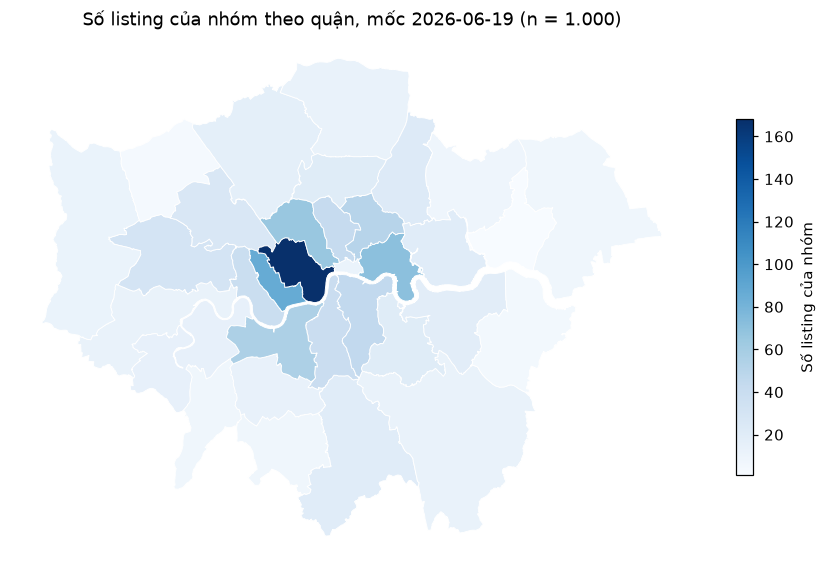

neighbourhood_cleansed,Barking and Dagenham,Harrow,Bexley,Kingston upon Thames,Havering,Sutton,Redbridge,City of London
so_listing,1,4,5,8,8,8,9,12


In [7]:
so_listing_quan = gdf["neighbourhood_cleansed"].value_counts().rename("so_listing")
quan_mau = quan.merge(so_listing_quan, left_on="neighbourhood", right_index=True, how="left", validate="one_to_one")
# Quận không có listing nào được ghi 0 vì đây là số đếm, không phải một giá trị chưa biết (Bài 13).
quan_mau["so_listing"] = quan_mau["so_listing"].fillna(0)

fig, ax = plt.subplots(figsize=(10, 7))
quan_mau.plot(column="so_listing", cmap="Blues", edgecolor="white", linewidth=0.6, legend=True, ax=ax,
              legend_kwds={"label": "Số listing của nhóm", "shrink": 0.6})
ax.set_title(f"Số listing của nhóm theo quận, mốc {moc_gia} (n = 1.000)")
ax.set_axis_off()
plt.show()

so_listing_quan.sort_values().head(8).to_frame().T   # Tám quận có ít listing nhất

Bản đồ xác nhận điều đã thấy ở notebook 02. Mẫu tập trung ở Westminster và các quận trung tâm, còn rìa phía đông và phía nam chỉ có lác đác vài
listing. Bản đồ này mô tả mẫu của nhóm, không phải mật độ Airbnb của cả London, nên nếu đưa nó vào báo cáo thì chú thích phải nói rõ điều đó.

Các phát hiện của năm notebook được gom lại trong `06_tong_hop.ipynb`.